In [13]:
import hashlib
import os
import platform
import uuid
import sys

STUDENT_ID = 20244080122
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")
print(f"[Python] {sys.version.split()[0]}")


[Conda 环境] None
[学号] 20244080122
[机器指纹] b1eeb302b80bf458
[RUN_ID] 20244080122-b1eeb302b80bf458
[Python] 3.14.9


In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


In [15]:
def wigner_density(x):
    if abs(x) <= 2:
        return 1/(2*np.pi) * np.sqrt(4 - x**2)
    else:
        return 0


In [16]:
def generate_wigner(n):
    if not (isinstance(n, int) and n > 0):
        raise ValueError("n必须是正整数")
    Z = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            val = np.random.normal(loc=0, scale=1/np.sqrt(n))
            Z[i,j] = val
            Z[j,i] = val
    return Z


In [17]:
def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    eigvals.sort()
    return eigvals


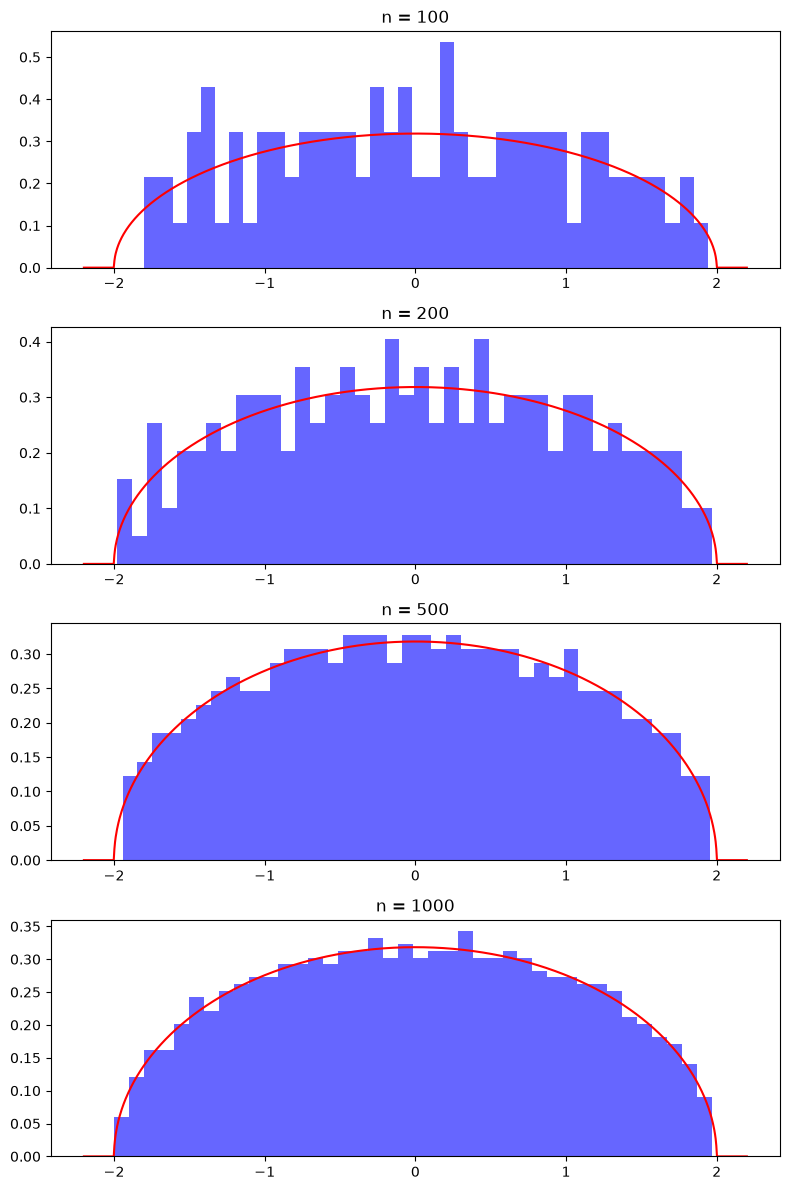

In [18]:
ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4,1, figsize=(8,12))
x_curve = np.linspace(-2.2, 2.2, 1000)
y_curve = np.array([wigner_density(x) for x in x_curve])

for ax, n in zip(axes, ns):
    mat = generate_wigner(n)
    eig = get_spectrum(mat)
    ax.hist(eig, bins=40, density=True, color="blue", alpha=0.6)
    ax.plot(x_curve, y_curve, color="red")
    ax.set_title(f"n = {n}")

plt.tight_layout()
plt.show()


观察：随着n增大，特征值直方图越来越贴近红色半圆密度曲线。n大约500以上，拟合效果已经比较好。


In [19]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    unique_vals = np.unique(board)
    for v in unique_vals:
        if v not in (0,1):
            return False
    return True


In [20]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘不合法，必须二维且只有0/1")
    m, n = board.shape
    next_board = np.zeros_like(board)
    for i in range(m):
        for j in range(n):
            neighbors = 0
            for di in (-1,0,1):
                for dj in (-1,0,1):
                    if di==0 and dj==0:
                        continue
                    ni = (i + di) % m
                    nj = (j + dj) % n
                    neighbors += board[ni, nj]
            cur = board[i,j]
            if cur == 1:
                if neighbors ==2 or neighbors ==3:
                    next_board[i,j] = 1
                else:
                    next_board[i,j]=0
            else:
                if neighbors ==3:
                    next_board[i,j]=1
                else:
                    next_board[i,j]=0
    return next_board


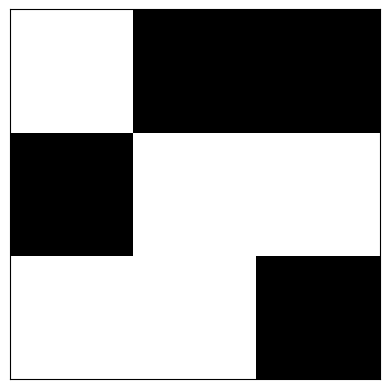

In [21]:
def draw_gol_board(board):
    plt.imshow(board, cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.show()

test_board = np.array([[1,0,0],[0,1,1],[1,1,0]])
draw_gol_board(test_board)


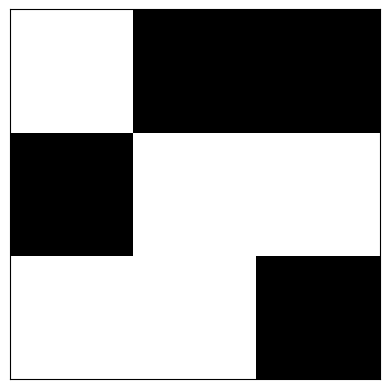

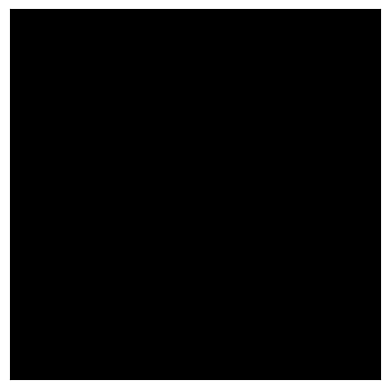

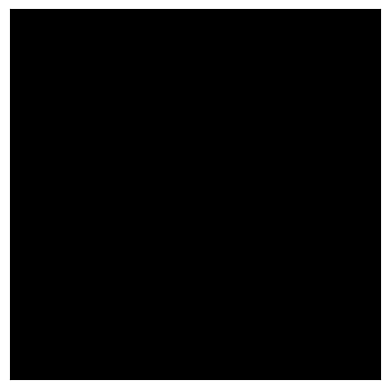

In [22]:
# 初始棋盘
board = np.array([[1,0,0],[0,1,1],[1,1,0]])
draw_gol_board(board)

# 迭代一步
board = gol_step(board)
draw_gol_board(board)

# 再迭代一步
board = gol_step(board)
draw_gol_board(board)


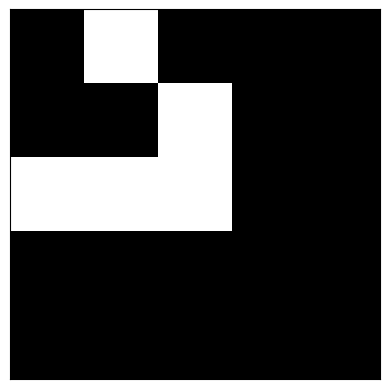

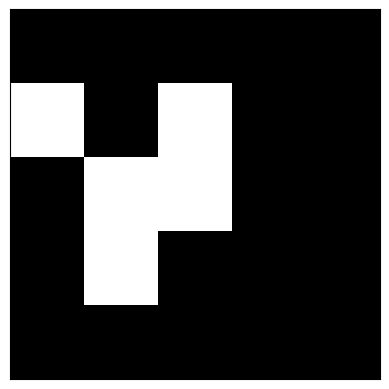

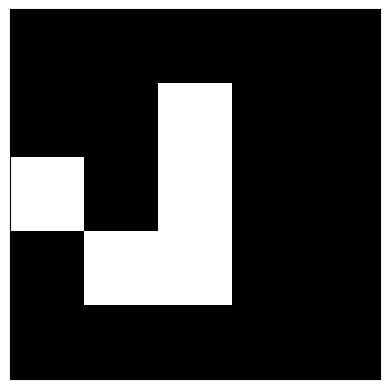

In [23]:
# 滑翔机 5*5
board = np.array([
    [0,1,0,0,0],
    [0,0,1,0,0],
    [1,1,1,0,0],
    [0,0,0,0,0],
    [0,0,0,0,0]
])
draw_gol_board(board)
board = gol_step(board)
draw_gol_board(board)
board = gol_step(board)
draw_gol_board(board)
